In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Retail sales analysis libraries are ready!")

Retail sales analysis libraries are ready!


In [2]:
np.random.seed(42)

n = 500

df = pd.DataFrame({
    "Order_ID": range(1001, 1001 + n),
    "Order_Date": pd.to_datetime(
        np.random.choice(
            pd.date_range("2025-01-01", "2025-12-31"),
            n
        )
    ),
    "Region": np.random.choice(
        ["North", "South", "East", "West"], n
    ),
    "Category": np.random.choice(
        ["Electronics", "Clothing", "Home & Kitchen", "Beauty"],
        n
    ),
    "Quantity": np.random.randint(1, 10, n),
    "Unit_Price": np.random.randint(100, 5001, n),
    "Customer_Type": np.random.choice(
        ["New", "Returning"], n
    )
})

df["Sales"] = df["Quantity"] * df["Unit_Price"]

display(df.head(10))

,Order_ID,Order_Date,Region,Category,Quantity,Unit_Price,Customer_Type,Sales
0,1001,2025-04-13,East,Electronics,1,3244,Returning,3244
1,1002,2025-12-15,South,Beauty,8,2370,New,18960
2,1003,2025-09-28,North,Clothing,3,1539,Returning,4617
3,1004,2025-04-17,West,Clothing,2,652,Returning,1304
4,1005,2025-03-13,West,Clothing,1,815,New,815
5,1006,2025-07-08,West,Electronics,3,4011,Returning,12033
6,1007,2025-01-21,East,Clothing,2,1813,New,3626
7,1008,2025-04-13,West,Clothing,2,3489,New,6978
8,1009,2025-05-02,West,Electronics,6,1207,Returning,7242
9,1010,2025-08-03,West,Home & Kitchen,1,4306,New,4306


In [3]:
print("Dataset shape:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

print("\nFirst 5 records:")
display(df.head())

print("\nLast 5 records:")
display(df.tail())

Dataset shape: (500, 8)

Column names:
['Order_ID', 'Order_Date', 'Region', 'Category', 'Quantity', 'Unit_Price', 'Customer_Type', 'Sales']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 8 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   Order_ID       500 non-null    int64         
 1   Order_Date     500 non-null    datetime64[ns]
 2   Region         500 non-null    object        
 3   Category       500 non-null    object        
 4   Quantity       500 non-null    int64         
 5   Unit_Price     500 non-null    int64         
 6   Customer_Type  500 non-null    object        
 7   Sales          500 non-null    int64         
dtypes: datetime64[ns](1), int64(4), object(3)
memory usage: 31.4+ KB

First 5 records:


,Order_ID,Order_Date,Region,Category,Quantity,Unit_Price,Customer_Type,Sales
0,1001,2025-04-13,East,Electronics,1,3244,Returning,3244
1,1002,2025-12-15,South,Beauty,8,2370,New,18960
2,1003,2025-09-28,North,Clothing,3,1539,Returning,4617
3,1004,2025-04-17,West,Clothing,2,652,Returning,1304
4,1005,2025-03-13,West,Clothing,1,815,New,815



Last 5 records:


,Order_ID,Order_Date,Region,Category,Quantity,Unit_Price,Customer_Type,Sales
495,1496,2025-11-21,South,Beauty,8,4238,New,33904
496,1497,2025-01-04,North,Home & Kitchen,3,4449,Returning,13347
497,1498,2025-01-16,South,Clothing,6,3301,New,19806
498,1499,2025-10-07,North,Beauty,9,2810,Returning,25290
499,1500,2025-12-02,North,Clothing,6,2053,Returning,12318


In [4]:
print("Missing values:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())
print("Unique order IDs:", df["Order_ID"].nunique())

print("\nData types:")
print(df.dtypes)

Missing values:
Order_ID         0
Order_Date       0
Region           0
Category         0
Quantity         0
Unit_Price       0
Customer_Type    0
Sales            0
dtype: int64

Duplicate rows: 0
Unique order IDs: 500

Data types:
Order_ID                  int64
Order_Date       datetime64[ns]
Region                   object
Category                 object
Quantity                  int64
Unit_Price                int64
Customer_Type            object
Sales                     int64
dtype: object


In [5]:
print("Numerical summary:")
display(df.describe().round(2))

print("\nCategory summary:")
display(df.describe(include="object"))

print("\nProduct category counts:")
print(df["Category"].value_counts())

print("\nRegion counts:")
print(df["Region"].value_counts())

Numerical summary:


,Order_ID,Order_Date,Quantity,Unit_Price,Sales
count,500.00,500,500.00,500.00,500.00
mean,1250.50,2025-07-05 18:14:24,4.92,2549.02,12776.14
min,1001.00,2025-01-01 00:00:00,1.00,101.00,111.00
25%,1125.75,2025-04-12 12:00:00,2.00,1340.50,4057.25
50%,1250.50,2025-07-06 00:00:00,5.00,2593.50,9738.50
75%,1375.25,2025-10-01 06:00:00,7.00,3787.75,19080.00
max,1500.00,2025-12-31 00:00:00,9.00,4995.00,44856.00
std,144.48,NaN,2.66,1414.13,10791.83



Category summary:


,Region,Category,Customer_Type
count,500,500,500
unique,4,4,2
top,North,Home & Kitchen,Returning
freq,151,133,257



Product category counts:
Category
Home & Kitchen    133
Clothing          130
Electronics       126
Beauty            111
Name: count, dtype: int64

Region counts:
Region
North    151
East     118
South    116
West     115
Name: count, dtype: int64


In [6]:
total_orders = df["Order_ID"].nunique()
total_units = df["Quantity"].sum()
total_sales = df["Sales"].sum()
average_order_value = df["Sales"].mean()
average_unit_price = df["Unit_Price"].mean()

print("Total Orders:", total_orders)
print("Total Units Sold:", total_units)
print(f"Total Sales: {total_sales:,.2f}")
print(f"Average Order Value: {average_order_value:,.2f}")
print(f"Average Unit Price: {average_unit_price:,.2f}")
print("Product Categories:", df["Category"].nunique())
print("Regions:", df["Region"].nunique())

Total Orders: 500
Total Units Sold: 2461
Total Sales: 6,388,070.00
Average Order Value: 12,776.14
Average Unit Price: 2,549.02
Product Categories: 4
Regions: 4


,Total_Sales
Category,
Home & Kitchen,1819808
Electronics,1653462
Clothing,1532835
Beauty,1381965


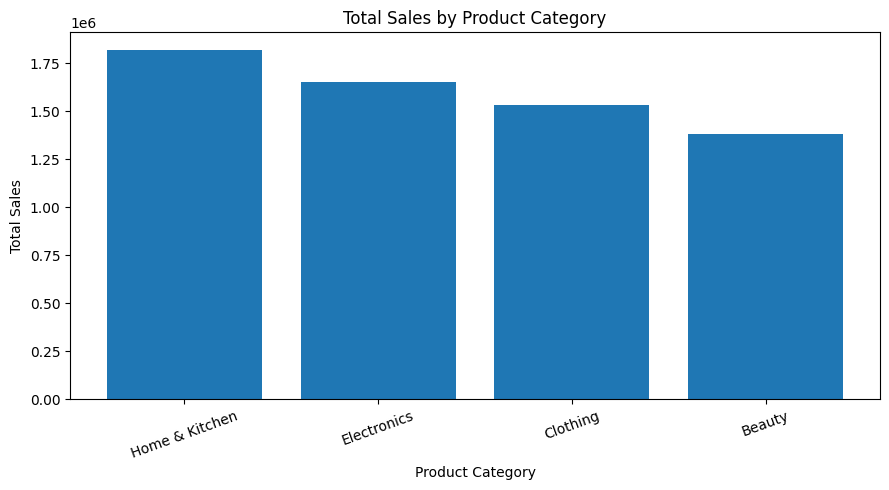

In [7]:
category_sales = (
    df.groupby("Category")["Sales"]
    .sum()
    .sort_values(ascending=False)
)

display(category_sales.to_frame("Total_Sales").round(2))

plt.figure(figsize=(9, 5))
plt.bar(category_sales.index, category_sales.values)
plt.title("Total Sales by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Total Sales")
plt.xticks(rotation=20)
plt.tight_layout()
plt.savefig("1_sales_by_category.png", dpi=300, bbox_inches="tight")
plt.show()

,Total_Sales
Region,
East,1658093
North,1653957
West,1603822
South,1472198


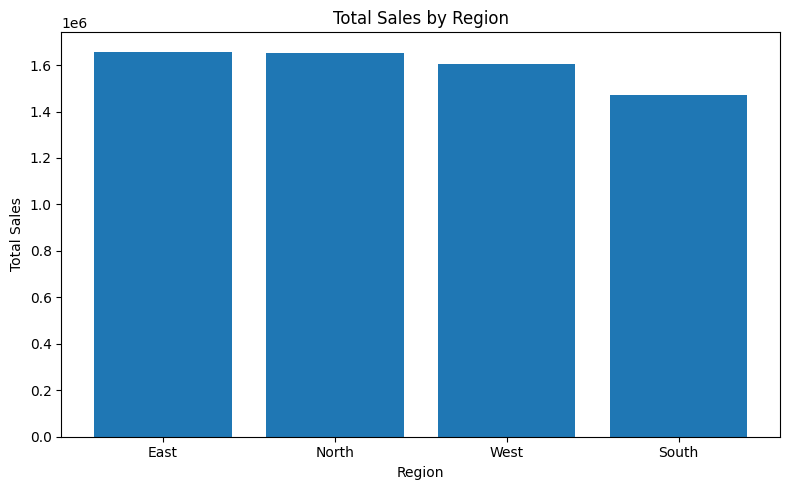

In [8]:
region_sales = (
    df.groupby("Region")["Sales"]
    .sum()
    .sort_values(ascending=False)
)

display(region_sales.to_frame("Total_Sales").round(2))

plt.figure(figsize=(8, 5))
plt.bar(region_sales.index, region_sales.values)
plt.title("Total Sales by Region")
plt.xlabel("Region")
plt.ylabel("Total Sales")
plt.tight_layout()
plt.savefig("2_sales_by_region.png", dpi=300, bbox_inches="tight")
plt.show()

,Total_Sales
Month,
2025-01,386717
2025-02,580529
2025-03,399784
2025-04,644277
2025-05,614133
2025-06,600505
2025-07,595048
2025-08,507698
2025-09,616333


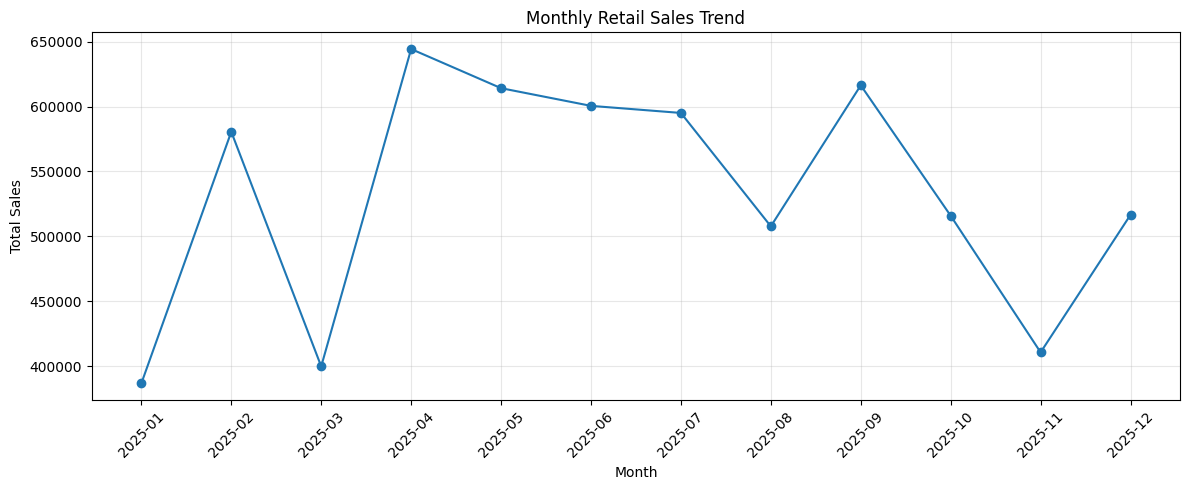

In [9]:
df["Month"] = df["Order_Date"].dt.to_period("M").astype(str)

monthly_sales = df.groupby("Month")["Sales"].sum()

display(monthly_sales.to_frame("Total_Sales").round(2))

plt.figure(figsize=(12, 5))
plt.plot(monthly_sales.index, monthly_sales.values, marker="o")
plt.title("Monthly Retail Sales Trend")
plt.xlabel("Month")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig("3_monthly_sales_trend.png", dpi=300, bbox_inches="tight")
plt.show()

,Units_Sold
Category,
Home & Kitchen,657
Electronics,651
Clothing,623
Beauty,530


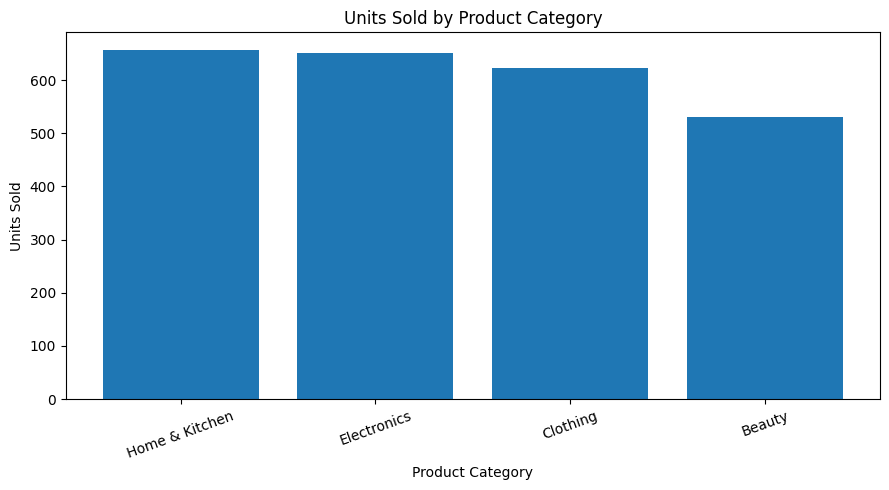

In [10]:
category_quantity = (
    df.groupby("Category")["Quantity"]
    .sum()
    .sort_values(ascending=False)
)

display(category_quantity.to_frame("Units_Sold"))

plt.figure(figsize=(9, 5))
plt.bar(category_quantity.index, category_quantity.values)
plt.title("Units Sold by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Units Sold")
plt.xticks(rotation=20)
plt.tight_layout()
plt.savefig("4_units_sold_by_category.png", dpi=300, bbox_inches="tight")
plt.show()

,Total_Sales,Orders,Average_Order_Value
Customer_Type,,,
New,3013452,243,12401.04
Returning,3374618,257,13130.81


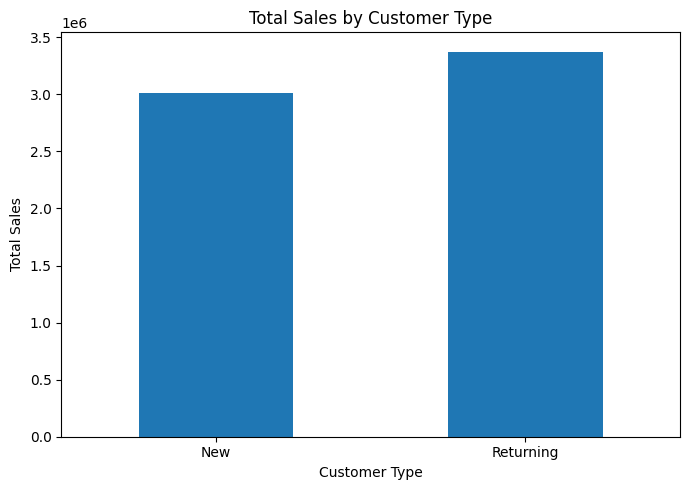

In [11]:
customer_sales = (
    df.groupby("Customer_Type")
    .agg(
        Total_Sales=("Sales", "sum"),
        Orders=("Order_ID", "nunique"),
        Average_Order_Value=("Sales", "mean")
    )
)

display(customer_sales.round(2))

customer_sales["Total_Sales"].plot(
    kind="bar",
    figsize=(7, 5)
)

plt.title("Total Sales by Customer Type")
plt.xlabel("Customer Type")
plt.ylabel("Total Sales")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig("5_sales_by_customer_type.png", dpi=300, bbox_inches="tight")
plt.show()

,Quantity,Unit_Price,Sales
Quantity,1.00,0.06,0.67
Unit_Price,0.06,1.00,0.69
Sales,0.67,0.69,1.00


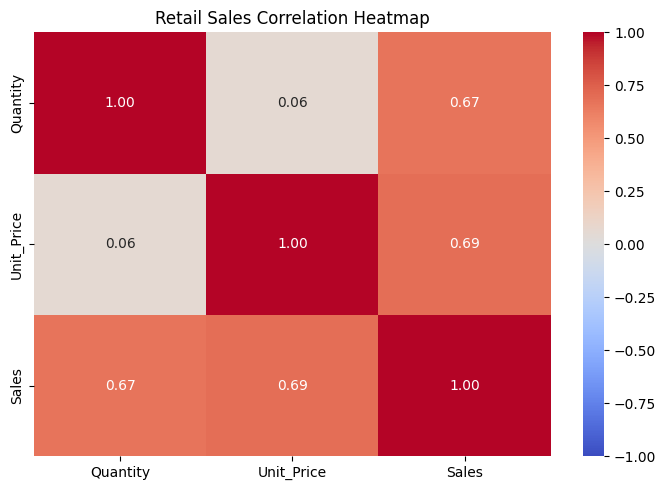

In [12]:
numeric_columns = [
    "Quantity",
    "Unit_Price",
    "Sales"
]

correlation = df[numeric_columns].corr()

display(correlation.round(2))

plt.figure(figsize=(7, 5))
sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    fmt=".2f"
)

plt.title("Retail Sales Correlation Heatmap")
plt.tight_layout()
plt.savefig("6_sales_correlation_heatmap.png", dpi=300, bbox_inches="tight")
plt.show()

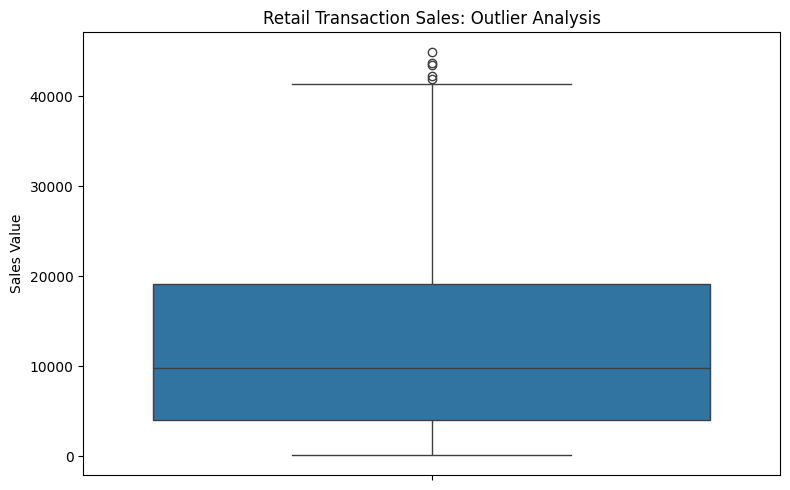

Potential outlier transactions: 5


,Order_ID,Category,Quantity,Unit_Price,Sales
103,1104,Electronics,9,4699,42291
258,1259,Beauty,9,4860,43740
281,1282,Home & Kitchen,9,4984,44856
417,1418,Electronics,9,4825,43425
425,1426,Home & Kitchen,9,4651,41859


In [13]:
plt.figure(figsize=(8, 5))
sns.boxplot(y=df["Sales"])
plt.title("Retail Transaction Sales: Outlier Analysis")
plt.ylabel("Sales Value")
plt.tight_layout()
plt.savefig("7_sales_outlier_boxplot.png", dpi=300, bbox_inches="tight")
plt.show()

Q1 = df["Sales"].quantile(0.25)
Q3 = df["Sales"].quantile(0.75)
IQR = Q3 - Q1

lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

outliers = df[
    (df["Sales"] < lower_limit)
    | (df["Sales"] > upper_limit)
]

print("Potential outlier transactions:", len(outliers))
display(
    outliers[
        ["Order_ID", "Category", "Quantity", "Unit_Price", "Sales"]
    ].head(10)
)

Region,East,North,South,West
Category,,,,
Beauty,350475,312306,444551,274633
Clothing,408044,550792,284125,289874
Electronics,413243,347160,366813,526246
Home & Kitchen,486331,443699,376709,513069


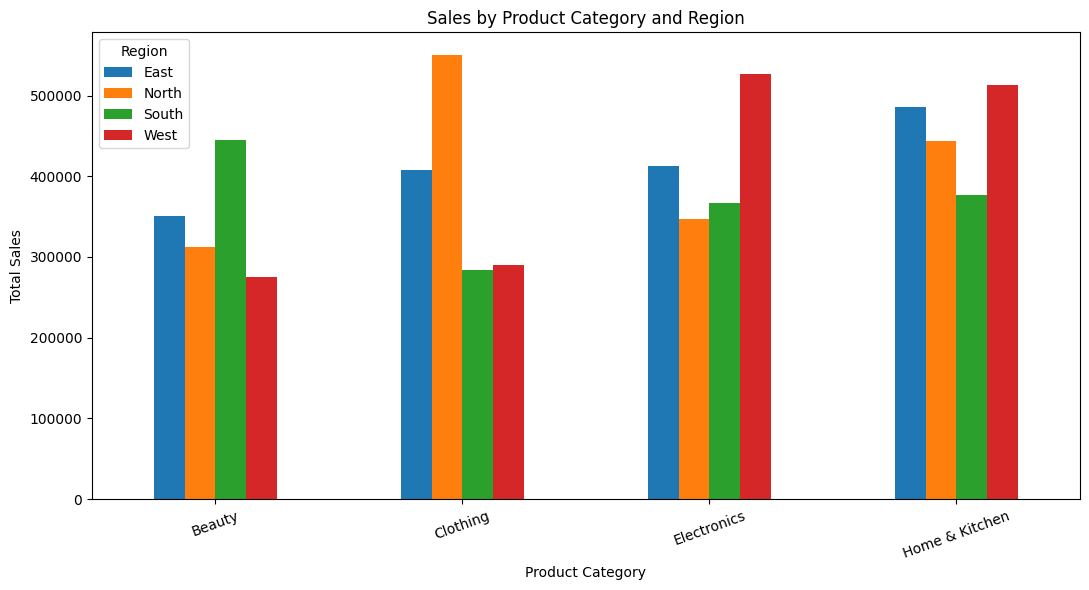

In [14]:
category_region = pd.pivot_table(
    df,
    values="Sales",
    index="Category",
    columns="Region",
    aggfunc="sum",
    fill_value=0
)

display(category_region.round(2))

category_region.plot(
    kind="bar",
    figsize=(11, 6)
)

plt.title("Sales by Product Category and Region")
plt.xlabel("Product Category")
plt.ylabel("Total Sales")
plt.xticks(rotation=20)
plt.legend(title="Region")
plt.tight_layout()
plt.savefig("8_category_sales_by_region.png", dpi=300, bbox_inches="tight")
plt.show()

In [15]:
category_summary = (
    df.groupby("Category")
    .agg(
        Total_Sales=("Sales", "sum"),
        Units_Sold=("Quantity", "sum"),
        Average_Transaction_Sales=("Sales", "mean"),
        Number_of_Orders=("Order_ID", "nunique")
    )
    .sort_values("Total_Sales", ascending=False)
)

display(category_summary.round(2))

,Total_Sales,Units_Sold,Average_Transaction_Sales,Number_of_Orders
Category,,,,
Home & Kitchen,1819808,657,13682.77,133
Electronics,1653462,651,13122.71,126
Clothing,1532835,623,11791.04,130
Beauty,1381965,530,12450.14,111


In [16]:
df.to_csv("retail_sales_analysis_dataset.csv", index=False)

print("Analyzed dataset saved successfully!")

Analyzed dataset saved successfully!


In [17]:
top_category = category_sales.idxmax()
top_category_sales = category_sales.max()

top_region = region_sales.idxmax()
top_region_sales = region_sales.max()

best_month = monthly_sales.idxmax()
best_month_sales = monthly_sales.max()

top_volume_category = category_quantity.idxmax()

top_customer_type = customer_sales["Total_Sales"].idxmax()

report = f"""
RETAIL SALES DATA ANALYSIS
Exploratory Data Analysis (EDA)

1. PROJECT OBJECTIVE
Analyze retail transaction data to explore sales performance,
product categories, regional patterns, customer types and trends.

2. DATASET OVERVIEW
- Total transactions: {len(df)}
- Product categories: {df['Category'].nunique()}
- Regions: {df['Region'].nunique()}
- Total units sold: {total_units}
- Missing values: {df.isnull().sum().sum()}
- Duplicate rows: {df.duplicated().sum()}

Note: This dataset is simulated for educational purposes.

3. KEY PERFORMANCE INDICATORS
- Total sales: {total_sales:,.2f}
- Average order value: {average_order_value:,.2f}
- Average unit price: {average_unit_price:,.2f}
- Total orders: {total_orders}

4. KEY FINDINGS
- Highest-revenue category: {top_category}
  Sales: {top_category_sales:,.2f}
- Highest-revenue region: {top_region}
  Sales: {top_region_sales:,.2f}
- Highest-sales month: {best_month}
  Sales: {best_month_sales:,.2f}
- Category with the highest unit volume: {top_volume_category}
- Customer type contributing the most sales: {top_customer_type}
- Potential sales outlier transactions identified: {len(outliers)}

5. BUSINESS RECOMMENDATIONS
- Review category-level revenue and unit volumes before planning stock.
- Compare regional sales when allocating inventory.
- Monitor monthly sales trends for future planning.
- Compare new and returning customer transaction patterns.
- Investigate unusual transaction values before taking action.

6. LIMITATIONS
The dataset is randomly generated and does not represent an
actual retailer. Results cannot establish genuine market demand,
seasonality or customer behaviour. Real transaction data would
be required to validate these patterns.

7. TOOLS
Python, Pandas, NumPy, Matplotlib, Seaborn and Google Colab.
"""

with open(
    "Retail_Sales_Business_Insights_Report.txt",
    "w",
    encoding="utf-8"
) as f:
    f.write(report)

print(report)
print("\nBusiness insights report saved!")


RETAIL SALES DATA ANALYSIS
Exploratory Data Analysis (EDA)

1. PROJECT OBJECTIVE
Analyze retail transaction data to explore sales performance,
product categories, regional patterns, customer types and trends.

2. DATASET OVERVIEW
- Total transactions: 500
- Product categories: 4
- Regions: 4
- Total units sold: 2461
- Missing values: 0
- Duplicate rows: 0

Note: This dataset is simulated for educational purposes.

3. KEY PERFORMANCE INDICATORS
- Total sales: 6,388,070.00
- Average order value: 12,776.14
- Average unit price: 2,549.02
- Total orders: 500

4. KEY FINDINGS
- Highest-revenue category: Home & Kitchen
  Sales: 1,819,808.00
- Highest-revenue region: East
  Sales: 1,658,093.00
- Highest-sales month: 2025-04
  Sales: 644,277.00
- Category with the highest unit volume: Home & Kitchen
- Customer type contributing the most sales: Returning
- Potential sales outlier transactions identified: 5

5. BUSINESS RECOMMENDATIONS
- Review category-level revenue and unit volumes before plan

In [18]:
import zipfile
import os

project_files = [
    "retail_sales_analysis_dataset.csv",
    "Retail_Sales_Business_Insights_Report.txt",
    "1_sales_by_category.png",
    "2_sales_by_region.png",
    "3_monthly_sales_trend.png",
    "4_units_sold_by_category.png",
    "5_sales_by_customer_type.png",
    "6_sales_correlation_heatmap.png",
    "7_sales_outlier_boxplot.png",
    "8_category_sales_by_region.png"
]

with zipfile.ZipFile(
    "Retail_Sales_Analysis_Project_Files.zip", "w"
) as z:
    for file in project_files:
        if os.path.exists(file):
            z.write(file)

print("Project ZIP created!")

Project ZIP created!


In [19]:
from google.colab import files

files.download("Retail_Sales_Analysis_Project_Files.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>